In [32]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
FIG = Path("../outputs/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet("../data/processed/cleaned_merged.parquet")
holidays = pd.read_csv("../data/raw/holidays_events.csv", parse_dates=["date"])

In [33]:
st = df.groupby(["store_nbr", "date"])["sales"].sum().reset_index()
open_date = st[st["sales"] > 0].groupby("store_nbr")["date"].min()
df["open_date"] = df["store_nbr"].map(open_date)

clean_p = df[(df["date"] >= "2015-07-01") & (df["date"] >= df["open_date"])]
daily_all = df.groupby("date")["sales"].sum()
tot = clean_p.groupby("date")["sales"].sum()
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

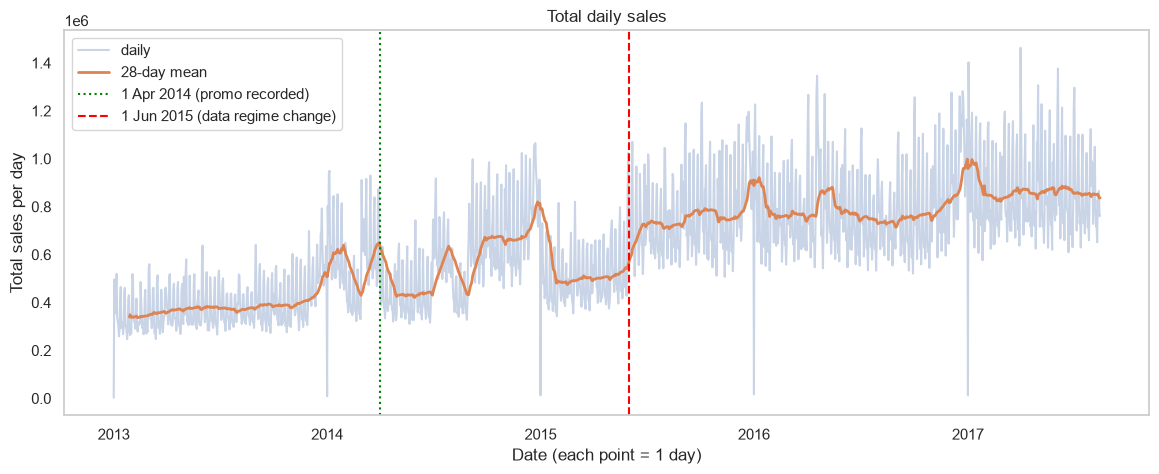

In [44]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_all.index, daily_all, alpha=0.3, label="daily")
ax.plot(daily_all.index, daily_all.rolling(28).mean(), lw=2, label="28-day mean")
ax.axvline(pd.Timestamp("2014-04-01"), color="green", ls=":", label="1 Apr 2014 (promo recorded)")
ax.axvline(pd.Timestamp("2015-06-01"), color="red", ls="--", label="1 Jun 2015 (data regime change)")
ax.set_xlabel("Date (each point = 1 day)")
ax.set_ylabel("Total sales per day")
ax.set_title("Total daily sales")
ax.grid(False)          
ax.legend()
fig.savefig(FIG / "dailysales.png", dpi=150, bbox_inches="tight")
plt.show()

Line plot
Date vs Total Sales per day
Finding: Sales go up over time (about 0.35M to 0.85M per day) and they are highest every December.  The messy ups and downs before June 2015 and the sudden jump after it are most likely caused by how the data was recorded (Produce, Home Care and Beverages sales were not recorded properly) not by real changes in customer demand.

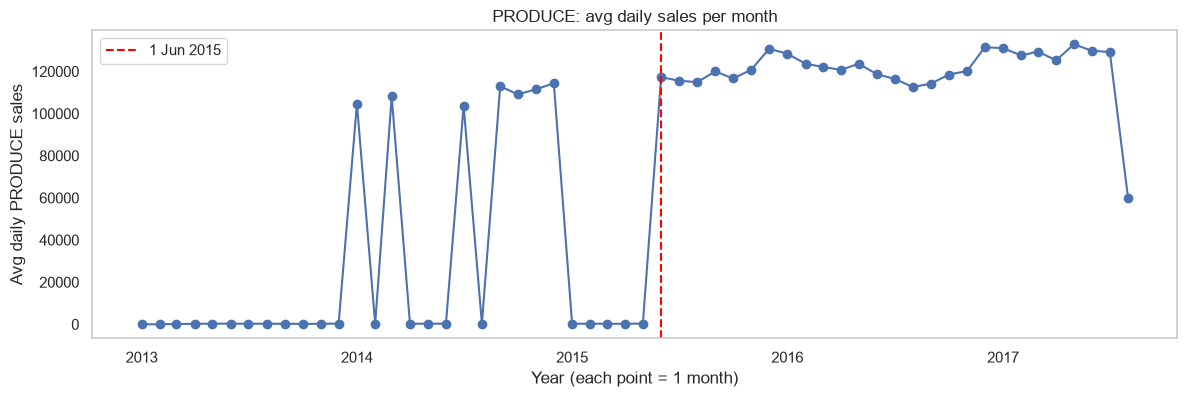

In [48]:
pr = df[df["family"] == "PRODUCE"].groupby(df["date"].dt.to_period("M"))["sales"].sum()
pr = pr / pr.index.days_in_month
pr.index = pr.index.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(pr.index, pr, marker="o")
ax.axvline(pd.Timestamp("2015-06-01"), color="red", ls="--", label="1 Jun 2015")
ax.set_xlabel("Year (each point = 1 month)")
ax.set_ylabel("Avg daily PRODUCE sales")
ax.set_title("PRODUCE: avg daily sales per month")
ax.grid(False)
ax.legend()
fig.savefig(FIG / "produceanomaly.png", dpi=150, bbox_inches="tight")
plt.show()

Line chart
Month vs Average daily PRODUCE sales (all stores added together)
Finding: PRODUCE sales are almost zero for all of 2013 and for most of 2014 to mid-2015 with only a few months where they suddenly appear (105k to 115k per day). From June 2015 onwards, sales are steady every month (about 115k to 130k per day). This shows PRODUCE data was not recorded properly before June 2015 so those zeros are missing data not real zero sales. The drop at the very end (Aug 2017) is not a real fall in sales, it is because that month is incomplete in dataset.

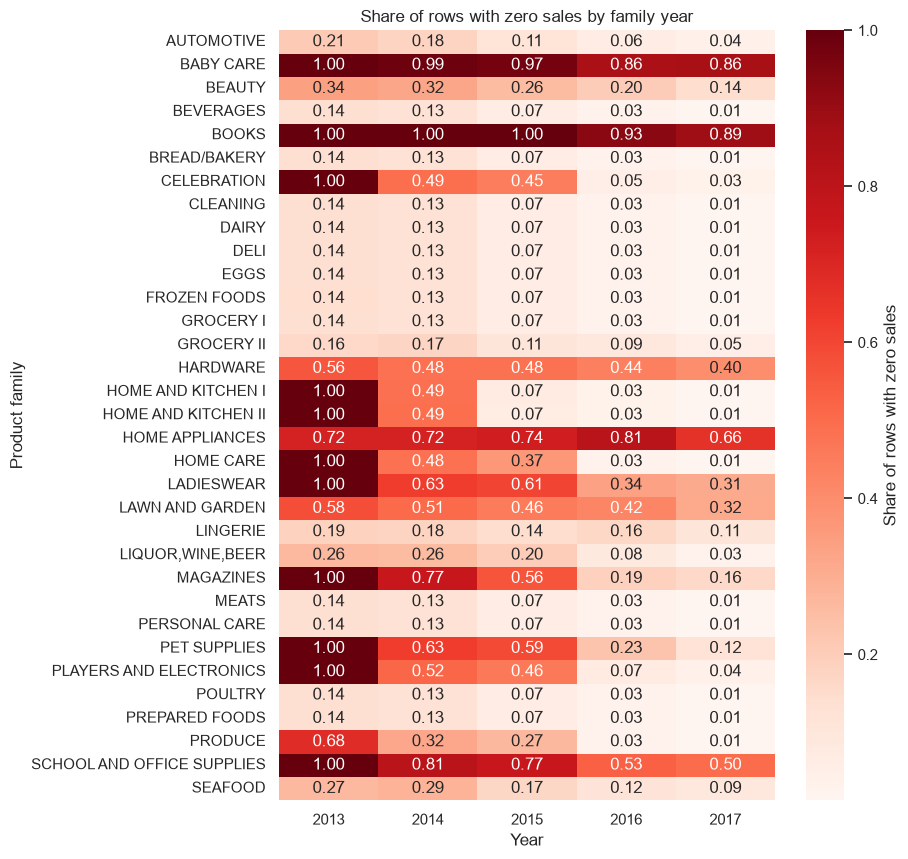

In [51]:
zr = (df.assign(is_zero=df["sales"] == 0, year=df["date"].dt.year)
        .groupby(["family", "year"], observed=True)["is_zero"].mean().unstack())

fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(zr, annot=True, fmt=".2f", cmap="Reds", ax=ax,
            cbar_kws={"label": "Share of rows with zero sales"})
ax.set_xlabel("Year")
ax.set_ylabel("Product family")
ax.set_title("Share of rows with zero sales by family year")
ax.grid(False)
fig.savefig(FIG / "zeroshare.png", dpi=150, bbox_inches="tight")
plt.show()

Heat map
Year vs Product family (colour = share of rows with zero sales, 0 = never zero, 1 = always zero)
Finding: Most everyday families (Beverages, Dairy, Cleaning, Meats, etc.) have very few zeros and the share keeps falling every year (about 0.14 in 2013 to 0.01 in 2017) probably because of closed days and stores that had not opened yet. Some families are almost always zero (Baby Care, Books, Home Appliances, School and Office Supplies) which means they sell rarely and have many true zero days. Other families (Celebration, Home and Kitchen I/II, Home Care, Ladieswear, Magazines, Pet Supplies, Players and Electronics, Produce) are 1.00 or very high in 2013 and then drop sharply so they were most likely not recorded in the early years. Those early zeros are missing data, not real zero sales.

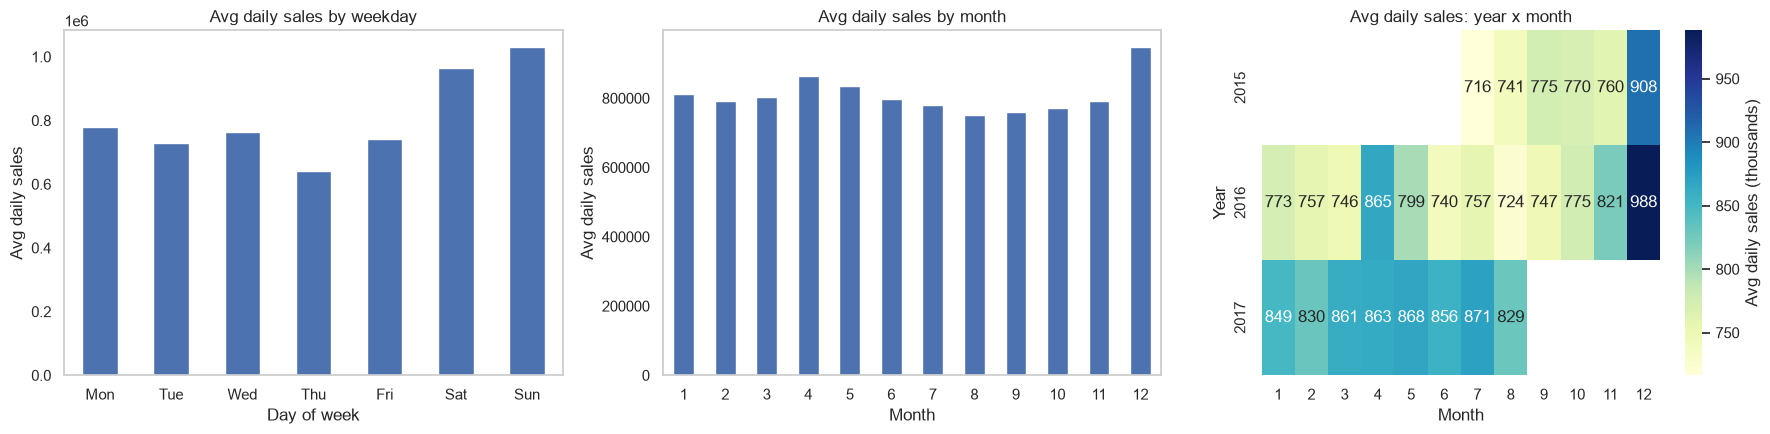

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Weekday
wd = tot.groupby(tot.index.dayofweek).mean()
wd.index = DAYS
wd.plot(kind="bar", ax=axes[0], title="Avg daily sales by weekday", rot=0)
axes[0].set_xlabel("Day of week")
axes[0].set_ylabel("Avg daily sales")

# 2. Month
tot.groupby(tot.index.month).mean().plot(kind="bar", ax=axes[1], title="Avg daily sales by month", rot=0)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Avg daily sales")

# 3. Year x month heatmap (values in thousands so numbers don't overlap)
piv = (tot.to_frame("s").assign(y=tot.index.year, m=tot.index.month)
          .pivot_table(index="y", columns="m", values="s")) / 1000
sns.heatmap(piv, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[2],
            cbar_kws={"label": "Avg daily sales (thousands)"})
axes[2].set_title("Avg daily sales: year x month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Year")

# grid off on all three
for ax in axes:
    ax.grid(False)

fig.tight_layout()
fig.savefig(FIG / "seasonality.png", dpi=150, bbox_inches="tight")
plt.show()

1-Bar chart
Day of week vs Average daily sales 
Finding: Sales are highest on weekends with Sunday the highest (about 1.0M) and Saturday next (about 0.95M). Thursday is the lowest (about 0.64M) and Monday to Friday stay in the 0.65M to 0.78M range. This shows a clear weekly pattern so day of week should be a feature in the model.
2-Bar chart
Month vs Average daily sales 
Finding: December is clearly the highest month (about 0.95M) most likely because of holiday shopping.April is high partly because of the 2016 earthquake but April 2017 is also high (863k) so monthly bars are also affected by growth. The other months are fairly flat (about 0.75M to 0.83M) with August the lowest.
3-Heat map
Month vs Year 
Finding: December is the darkest box each year (908k in 2015 and 988k in 2016) which confirms the yearly December peak. April 2016 (865k) stands out from its neighbours which matches the earthquake. In 2017 almost every month is higher than the same month in 2016 (about 830k to 870k vs 724k to 865k) which shows sales are still growing. Data starts from Jul 2015 and 2017 ends in Aug, so many boxes are empty.

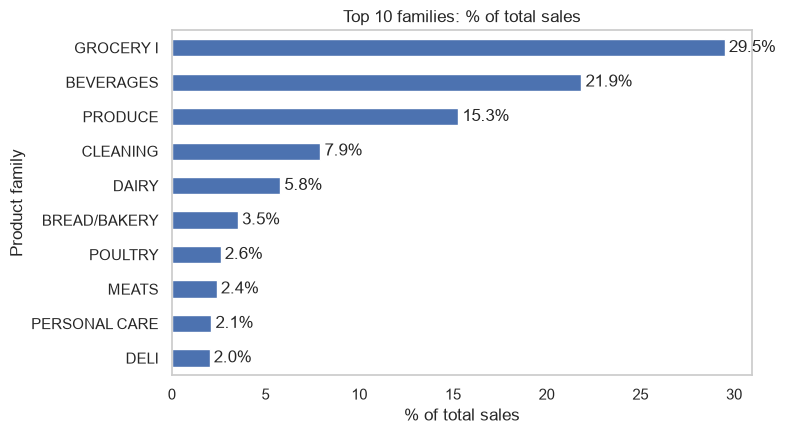

In [54]:
fs = clean_p.groupby("family", observed=True)["sales"].sum()
share = (fs / fs.sum() * 100).sort_values().tail(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
share.plot(kind="barh", ax=ax, title="Top 10 families: % of total sales")
ax.set_xlabel("% of total sales")
ax.set_ylabel("Product family")
ax.grid(False)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)   # har bar ke saath % likha aayega
fig.tight_layout()
fig.savefig(FIG / "topfamilies.png", dpi=150)
plt.show()

Bar chart (horizontal)
Product family vs % of total sales (top 10 families data from Jul 2015 onwards)
Finding: Sales are concentrated in a few families. GROCERY I (29.5%), BEVERAGES (21.9%) and PRODUCE (15.3%) together make about 67% of all sales and the top 5 (with CLEANING and DAIRY) make about 80%. The other families each add only 2% to 3.5%, and the remaining 23 families together make only about 7%. This means errors in the big families will affect the total forecast the most so they matter most for the model.

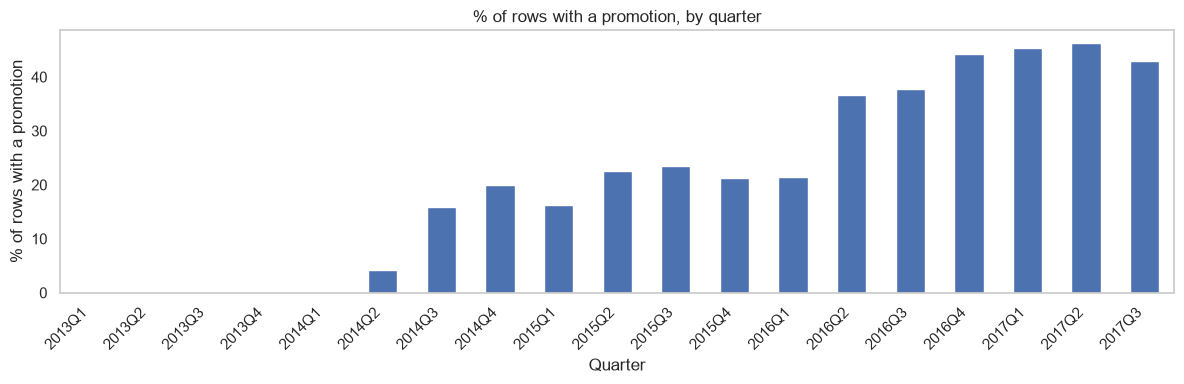

In [55]:
ps = df.assign(p=df["onpromotion"] > 0).groupby(df["date"].dt.to_period("Q"))["p"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ps.plot(kind="bar", ax=ax, title="% of rows with a promotion, by quarter")
ax.set_xlabel("Quarter")
ax.set_ylabel("% of rows with a promotion")
ax.grid(False)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")   # quarter labels parhne mein aasan
fig.tight_layout()
fig.savefig(FIG / "promoshare.png", dpi=150)
plt.show()

Bar chart
Quarter vs % of rows with a promotion
Finding: Promotions are 0% from 2013 until 2014Q1 and they start showing up in 2014Q2 (about 4%), so the earlier zeros mean "promo not recorded", not "no promo". After that the share grows step by step then jumps to about 37% in 2016Q2 and reaches about 44% to 46% by late 2016 and 2017. The share of promos keeps rising over time so promotions are used much more now than before and any model should use promo data only from 2014Q2 onwards.

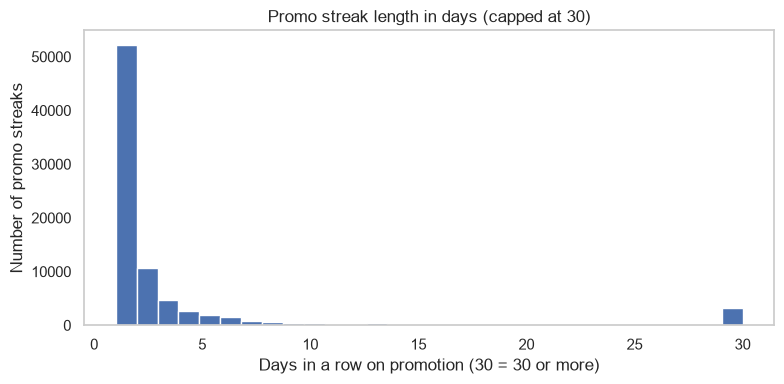

In [56]:
cp = clean_p.sort_values(["store_nbr", "family", "date"])
keys = [cp["store_nbr"], cp["family"]]
promo = pd.Series(cp["onpromotion"].to_numpy() > 0, index=cp.index)
chg = promo.ne(promo.groupby(keys, observed=True).shift())
run = chg.groupby(keys, observed=True).cumsum()
lens = promo[promo].groupby([cp["store_nbr"][promo], cp["family"][promo], run[promo]], observed=True).size()

fig, ax = plt.subplots(figsize=(8, 4))
lens.clip(upper=30).plot(kind="hist", bins=30, ax=ax, title="Promo streak length in days (capped at 30)")
ax.set_xlabel("Days in a row on promotion (30 = 30 or more)")
ax.set_ylabel("Number of promo streaks")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG / "promostreaks.png", dpi=150)
plt.show()

Histogram
Days in a row on promotion vs Number of promo streaks 
Finding: The data is strongly right-skewed. Most promotions are very short.A small group of streaks (about 3,000) sits at 30 which means those items were on promotion for 30 days or more in a row. This is not a real peak, it only looks like one because longer streaks were capped at 30. So promotions are mostly short one-or-two-day offers with a few long-running ones that act like outliers.

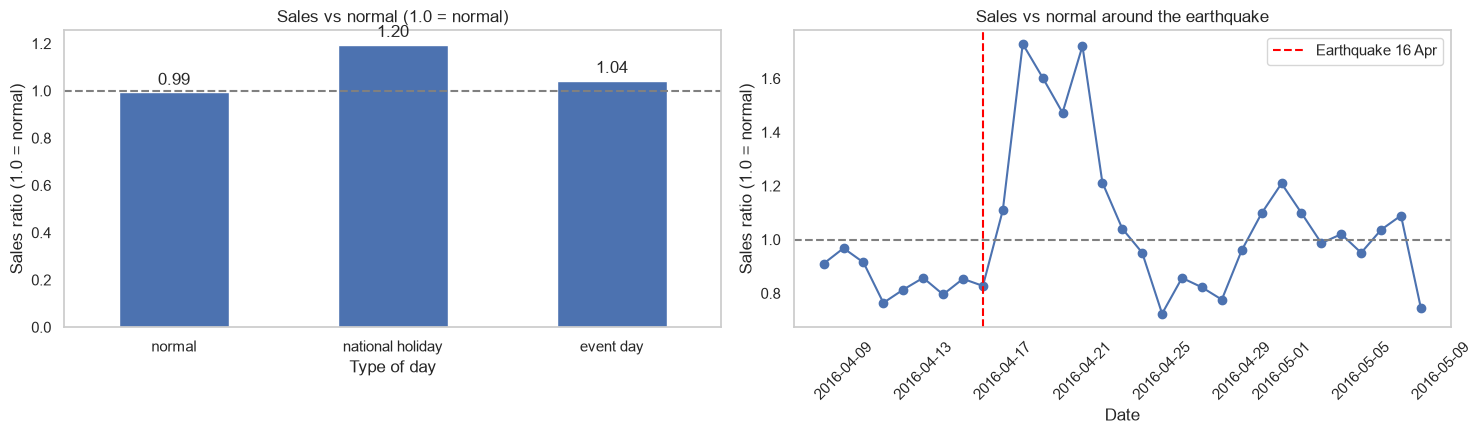

In [57]:
base = pd.concat([tot.shift(k) for k in (7, 14, -7, -14)], axis=1).mean(axis=1)
ratio = (tot / base).rename("ratio")
day_flags = clean_p.groupby("date")[["is_holiday_national", "is_event"]].max()
dd = pd.concat([ratio, day_flags], axis=1).dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# 1. Holiday / event vs normal
avg = pd.Series({
    "normal": dd.loc[(dd.is_holiday_national == 0) & (dd.is_event == 0), "ratio"].mean(),
    "national holiday": dd.loc[dd.is_holiday_national == 1, "ratio"].mean(),
    "event day": dd.loc[dd.is_event == 1, "ratio"].mean(),
})
avg.plot(kind="bar", ax=axes[0], rot=0, title="Sales vs normal (1.0 = normal)")
axes[0].axhline(1, color="grey", ls="--")
axes[0].set_xlabel("Type of day")
axes[0].set_ylabel("Sales ratio (1.0 = normal)")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=3)

# 2. Earthquake
eq = ratio["2016-04-08":"2016-05-08"]
axes[1].plot(eq.index, eq, marker="o")
axes[1].axhline(1, color="grey", ls="--")
axes[1].axvline(pd.Timestamp("2016-04-16"), color="red", ls="--", label="Earthquake 16 Apr")
axes[1].set_title("Sales vs normal around the earthquake")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Sales ratio (1.0 = normal)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.grid(False)

fig.tight_layout()
fig.savefig(FIG / "holidayearthquake.png", dpi=150, bbox_inches="tight")
plt.show()

1-Bar chart
Type of day vs Sales ratio (1.0 = normal)
Finding: Sales on normal days are right at the baseline (0.99). National holidays are clearly higher (1.20, so about 20% more sales than normal) while event days are only slightly higher (1.04). This means national holidays have a strong effect on sales so holiday flags should be used as model features while the event flag adds only a small average effect.
2-Line chart
Date vs Sales ratio (1.0 = normal)
Finding: Right after the earthquake (16 Apr 2016) sales jump sharply about 1.5 to 1.7 times normal from 18 to 21 April most likely because of panic buying and relief shopping. By about 23 April the ratio is back to around normal. The dips before the earthquake (about 0.8 to 0.85 on 14 and 15 April) and after the spike (about 0.72 on 25 April) are most likely an artifact of how the baseline is calculated, because the baseline uses days from the spike period. They are not real drops in demand. So the earthquake caused a short, sharp spike of about 4 days and a flag for those dates would help the model.

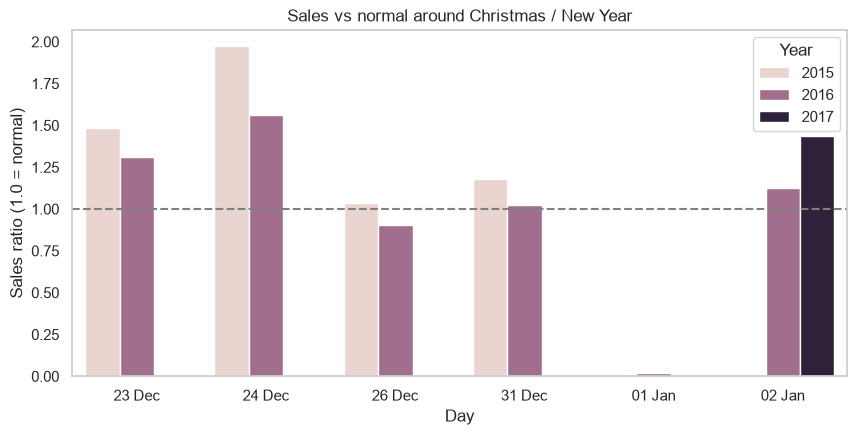

In [59]:
md = [(12,23),(12,24),(12,26),(12,31),(1,1),(1,2)]
xm = dd.loc[[d for d in dd.index if (d.month, d.day) in md], "ratio"]
xm = xm.to_frame().assign(year=xm.index.year, day=xm.index.strftime("%d %b"))
order = ["23 Dec", "24 Dec", "26 Dec", "31 Dec", "01 Jan", "02 Jan"]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=xm, x="day", y="ratio", hue="year", order=order, ax=ax)
ax.axhline(1, color="grey", ls="--")
ax.set_title("Sales vs normal around Christmas / New Year")
ax.set_xlabel("Day")
ax.set_ylabel("Sales ratio (1.0 = normal)")
ax.legend(title="Year")
ax.grid(False)
fig.savefig(FIG / "christmas.png", dpi=150, bbox_inches="tight")
plt.show()

Bar chart 
Day (around Christmas and New Year) vs Sales ratio (1.0 = normal)
Finding: Sales rush up just before Christmas. 23 Dec is about 1.3 to 1.5 times normal and 24 Dec is the highest day (about 2.0 in 2015 and 1.6 in 2016) most likely because of last-minute shopping. After Christmas sales come back to normal (26 Dec is about 0.9 to 1.0) and 31 Dec is only slightly above normal (about 1.0 to 1.2). On 1 Jan the ratio is almost zero because the stores are closed and 2 Jan is above normal again (about 1.1 in 2016 and 1.4 in 2017) probably because people shop again after the closure. The pattern is similar in every year.

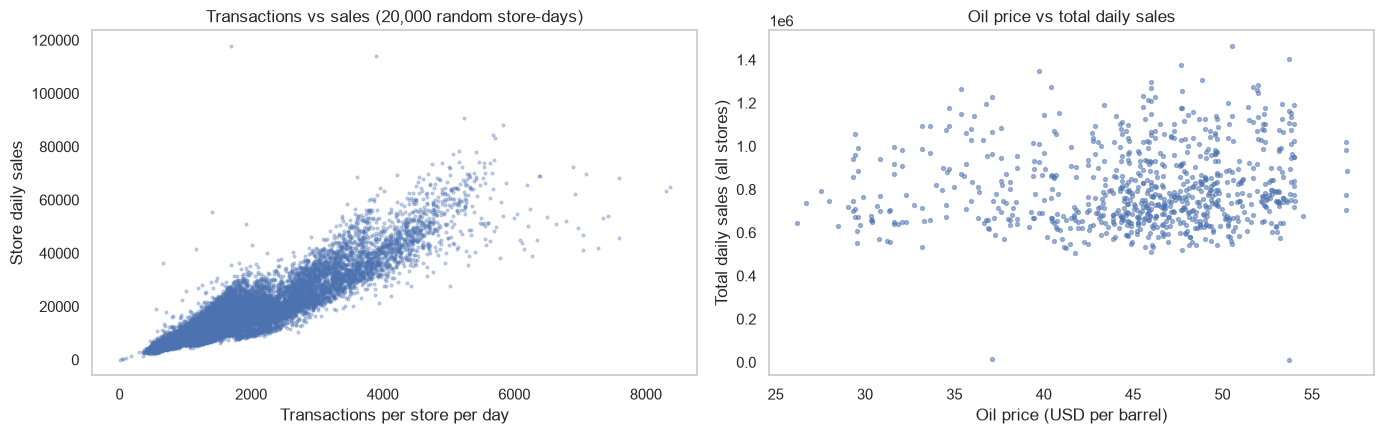

In [61]:
sd = (clean_p.groupby(["store_nbr", "date"])
             .agg(s=("sales", "sum"), t=("transactions", "first"))
             .reset_index().query("s > 0").sample(20000, random_state=42))
o = clean_p.groupby("date")[["dcoilwtico"]].first().join(tot)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Transactions vs sales
axes[0].scatter(sd["t"], sd["s"], s=4, alpha=0.3)
axes[0].set_xlabel("Transactions per store per day")
axes[0].set_ylabel("Store daily sales")
axes[0].set_title("Transactions vs sales (20,000 random store-days)")

# 2. Oil price vs sales
axes[1].scatter(o["dcoilwtico"], o["sales"], s=8, alpha=0.5)
axes[1].set_xlabel("Oil price (USD per barrel)")
axes[1].set_ylabel("Total daily sales (all stores)")
axes[1].set_title("Oil price vs total daily sales")

for ax in axes:
    ax.grid(False)

fig.tight_layout()
fig.savefig(FIG / "transactionoil.png", dpi=150, bbox_inches="tight")
plt.show()

1-Scatter plot
Transactions per store per day vs Store daily sales
Finding: There is a strong positive almost straight-line relationship so more transactions means more sales. The points spread out like a fan as transactions grow so for the same number of transactions the sales can differ a lot at higher levels (probably because customers buy different basket sizes in different stores). There are a few outliers.For example about 118k sales with only about 1,700 transactions and a few days with very high transactions (6,000 to 8,000).
2-Scatter plot
Oil price vs Total daily sales
Finding: The points form a random cloud with no clear pattern so oil price has little or no visible relationship with total sales. Sales stay between about 0.5M and 1.4M whether oil is at 30 or at 55. The two points near zero sales are 1 January (stores closed) so they are outliers for a known reason not an oil effect.

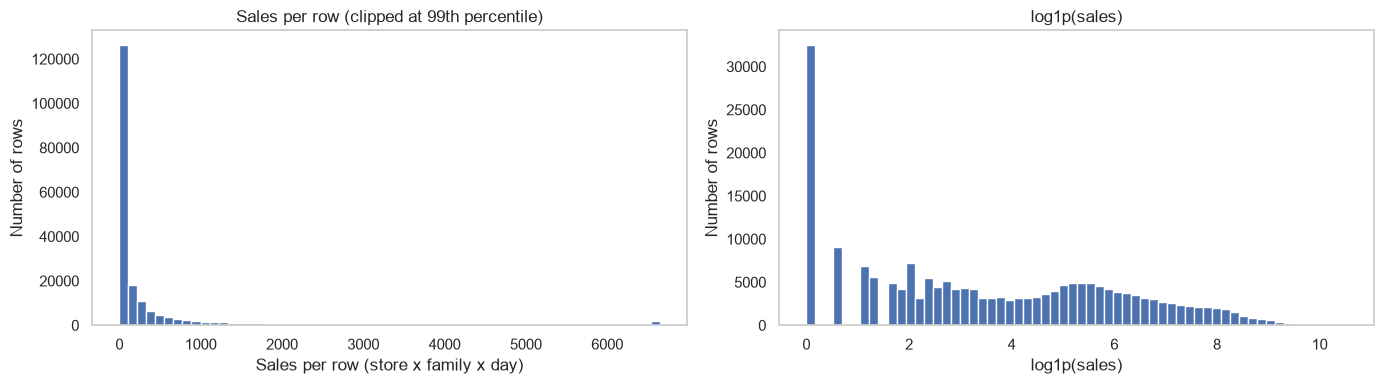

Skew (raw sales): 5.85
Skew (log1p): 0.21
Share of zero-sales rows: 16.3 %


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

smp = clean_p["sales"].sample(200000, random_state=42)

# 1. Raw sales (clipped at 99th percentile)
axes[0].hist(smp.clip(upper=smp.quantile(0.99)), bins=60)
axes[0].set_title("Sales per row (clipped at 99th percentile)")
axes[0].set_xlabel("Sales per row (store x family x day)")
axes[0].set_ylabel("Number of rows")

# 2. log1p(sales)
axes[1].hist(np.log1p(smp), bins=60)
axes[1].set_title("log1p(sales)")
axes[1].set_xlabel("log1p(sales)")
axes[1].set_ylabel("Number of rows")

for ax in axes:
    ax.grid(False)

fig.tight_layout()
fig.savefig(FIG / "salesdistribution.png", dpi=150, bbox_inches="tight")
plt.show()

# skewness numbers (findings mein likhne ke liye, alag cell mein chala lo)
print("Skew (raw sales):", round(smp.skew(), 2))
print("Skew (log1p):", round(np.log1p(smp).skew(), 2))
print("Share of zero-sales rows:", round((smp == 0).mean() * 100, 1), "%")

1-Histogram
Sales per row vs Number of rows
Finding: The data is strongly right-skewed (skewness = 5.85). About 126,000 of the 200,000 sampled rows (roughly 60%) have very small sales (below about 110) and the count drops quickly as sales get bigger. Most rows are small but a few rows are very large which act as outliers. The bar at about 6,600 is not a real peak. It is the top 1% of rows that were clipped to the 99th percentile value so it hides how big the largest sales really are.
2-Histogram
log1p(sales) vs Number of rows
Finding: After the log transform the skewness drops from 5.85 to 0.21 which is very close to symmetric and the main group of values forms a wide, bell-like hump around 5 to 6. The distribution is still not perfectly normal. There is a big spike at 0 (16.3% of rows have zero sales) which means many rows have no sales. There are also small bars at 0.7, 1.1, 1.4 and 2.0 because many rows sell only 1, 2, 3 or 4 items at a time. This is why a log transform helps the model and why zero sales need special attention.

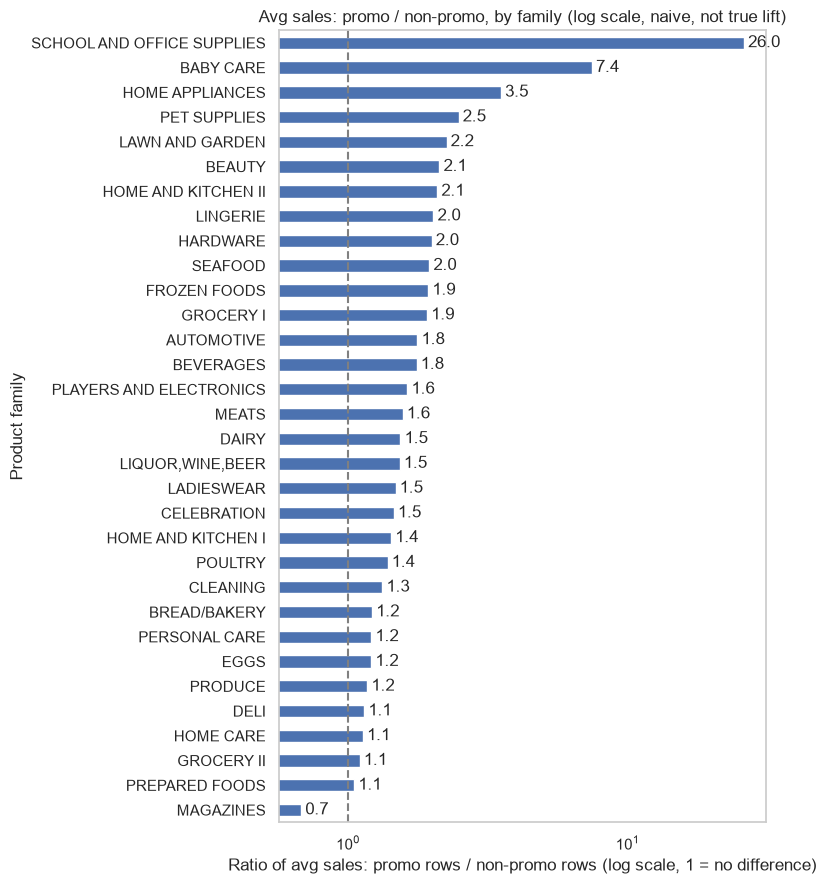

In [65]:
g = clean_p.assign(promo=clean_p["onpromotion"] > 0)
t = g.groupby(["family", "promo"], observed=True)["sales"].mean().unstack()
t = t.dropna()                                   # BOOKS ke paas promo rows nahi
ratio_f = (t[True] / t[False]).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ratio_f.plot(kind="barh", ax=ax, logx=True)
ax.axvline(1, color="grey", ls="--")
ax.set_title("Avg sales: promo / non-promo, by family (log scale, naive, not true lift)")
ax.set_xlabel("Ratio of avg sales: promo rows / non-promo rows (log scale, 1 = no difference)")
ax.set_ylabel("Product family")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)   # har bar par ratio
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG / "promovsnonpromo.png", dpi=150)
plt.show()

Bar chart (horizontal)
Product family vs Ratio of average sales on promo rows / non-promo rows 
Finding: For 31 of the 32 families, rows with a promotion have higher average sales than rows without one (ratio above 1). Most families sit between 1.1x and 2.1x, and big families such as GROCERY I (1.9) and BEVERAGES (1.8) are about 1.8x to 1.9x higher on promo. A few families are far above the rest: SCHOOL AND OFFICE SUPPLIES (26.0), BABY CARE (7.4), HOME APPLIANCES (3.5). Only MAGAZINES is below 1 (0.7). This is a naive comparison not the true effect of a promotion, so it only shows that promotion and high sales go together.

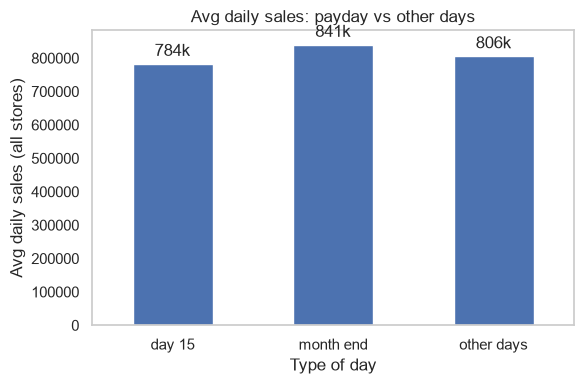

In [66]:
d = tot.to_frame("sales")
cat = np.where(d.index.day == 15, "day 15",
      np.where(d.index.is_month_end, "month end", "other days"))
pay = d.groupby(cat)["sales"].mean().reindex(["day 15", "month end", "other days"])

fig, ax = plt.subplots(figsize=(6, 4))
pay.plot(kind="bar", ax=ax, rot=0, title="Avg daily sales: payday vs other days")
ax.set_xlabel("Type of day")
ax.set_ylabel("Avg daily sales (all stores)")
ax.bar_label(ax.containers[0], labels=[f"{v/1000:.0f}k" for v in pay], padding=3)   # har bar par value (thousands)
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG / "payday.png", dpi=150)
plt.show()

Bar chart
Type of day vs Average daily sales 
Finding: The differences are small. Month-end days have the highest average sales (841k), about 4% above other days (806k). Day 15 is actually a bit lower (784k) about 3% below other days so there is a weak sign of a month-end effect but no sign of a boost on day 15. Payday timing is therefore a minor factor compared with weekday and December seasonality.